# Shapes3D — train, save and generate with concept-bottleneck VAEs

Pick a model in the **first code cell**, then *Run All*. Every model shares the same ConvVAE; only the bottleneck between `z` and the decoder changes.

| `MODEL` | aliases | bottleneck | concepts as |
|---|---|---|---|
| `"vae"` | `"baseline"` | none, plain VAE | — |
| `"cbm"` | | scalar CBM | values in [-1, 1] |
| `"cem"` | `"case3.5"` | CEM, binary-anchor interpolation (**Case 3.5**) | values in [-1, 1] |
| `"cem_linear"` | | CEMLinear, $c_i\,\phi_i(x)$ | values in [-1, 1] |
| `"categorical"` | `"case2"` | CEMCategorical, native states (**Case 2**) | state index |
| `"binned"` | `"case3"` | CEMCategorical over `N_BINS` bins (**Case 3**) | bin index |

Concepts are the 6 Shapes3D factors: `floor_hue, wall_hue, object_hue, scale, shape, orientation`.
Models save to `outputs/models/shapes3d_<model>[_<tag>]/`; set `TRAIN = False` to reload instead of retraining.
Same code from the terminal: `python scripts/train_shapes3d_gen.py --model case3.5 --epochs 20`.

In [1]:
# ============================ CHOOSE HERE ============================
MODEL      = "cem"        # "baseline" | "cbm" | "cem" (case3.5) | "cem_linear" | "categorical" (case2) | "binned" (case3)
TRAIN      = True         # False -> load the model saved in RUN_DIR instead of training
EPOCHS     = 20
N_SAMPLES  = 100_000      # random subset of the 480k images (None = all, ~6 GB RAM)
N_BINS     = 5            # "binned" / case3 only
CONCEPTS   = ["floor_hue", "wall_hue", "object_hue", "scale", "shape", "orientation"]
TAG        = None         # suffix for the save folder, e.g. "k10" -> shapes3d_binned_k10
TRAIN_OPTS = dict(        # any TrainConfig field
    concept_weight    = 100.0,
    intervention_prob = 0.5,
    cycle_weight      = 100.0,   # makes interventions actually change the image; 0 to disable
    lr                = 1e-3,
    batch_size        = 256,
)
SEED_Z     = 0            # latent seed used by the plots below
# =====================================================================

In [2]:
%matplotlib inline
import os, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

import torch
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as W
from IPython.display import display

from cbmc.data.shapes3d import get_shapes3d, FACTORS, NOMINAL
from scripts.train_shapes3d_gen import (train, load, resolve, default_out_dir,
                                        list_saved, get_device, Generator)

NAME    = resolve(MODEL)
RUN_DIR = default_out_dir(NAME, TAG)
DEVICE  = get_device()
print(f"model={NAME}  device={DEVICE}  run_dir={RUN_DIR.relative_to(ROOT)}")

def show(imgs, titles=None, nrow=8, size=1.6, suptitle=None):
    imgs = imgs.clamp(0, 1).cpu()
    n = len(imgs); ncol = min(nrow, n); nr = (n + ncol - 1) // ncol
    fig, axes = plt.subplots(nr, ncol, figsize=(ncol * size, nr * size), squeeze=False)
    for i, ax in enumerate(axes.flat):
        ax.axis("off")
        if i < n:
            ax.imshow(imgs[i].permute(1, 2, 0).numpy())
            if titles: ax.set_title(titles[i], fontsize=7)
    if suptitle: fig.suptitle(suptitle)
    plt.tight_layout(); plt.show()

model=cem  device=mps  run_dir=outputs/models/shapes3d_cem


## 1. Data
Loaded once and kept in memory, so re-running the training cell with another `MODEL` skips this.

Shapes3D: 90000 train / 10000 test, concepts=['floor_hue', 'wall_hue', 'object_hue', 'scale', 'shape', 'orientation']


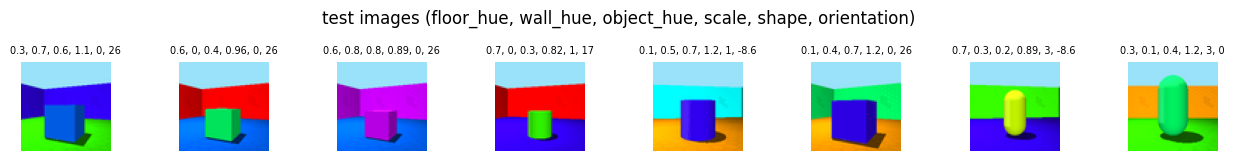

In [3]:
_key = (N_SAMPLES, tuple(CONCEPTS), TRAIN_OPTS.get("batch_size", 256))
if globals().get("_LOADERS_KEY") != _key:
    LOADERS = get_shapes3d(batch_size=_key[2], n_samples=N_SAMPLES, concepts=CONCEPTS)
    _LOADERS_KEY = _key
train_loader, test_loader = LOADERS
x_test, c_test, _ = next(iter(test_loader))
show(x_test[:8].float() / 255,
     titles=[", ".join(f"{v:.2g}" for v in c) for c in c_test[:8]],
     suptitle="test images (" + ", ".join(CONCEPTS) + ")")

## 2. Train (and save) — or load

In [4]:
if TRAIN:
    gen = train(NAME, epochs=EPOCHS, concepts=CONCEPTS, n_bins=N_BINS, n_samples=N_SAMPLES,
                tag=TAG, device=DEVICE, loaders=LOADERS, **TRAIN_OPTS)
else:
    gen = load(RUN_DIR, device=DEVICE)
print(gen)

Training cem on mps -> /Users/yassine/Desktop/CBMC/CBMC/outputs/models/shapes3d_cem
  concepts ['floor_hue', 'wall_hue', 'object_hue', 'scale', 'shape', 'orientation'] | mode continuous


epoch 1/20:   0%|          | 0/351 [00:00<?, ?it/s]

  epoch=1  recon=5212.1012  kl=77.3876  concept_loss=0.2921  cycle_loss=0.4033  test_recon=3961.0937  test_concept_mse=0.1528  test_concept_acc=0.4311


epoch 2/20:   0%|          | 0/351 [00:00<?, ?it/s]

  epoch=2  recon=3843.1467  kl=91.5608  concept_loss=0.1016  cycle_loss=0.2807  test_recon=3725.1716  test_concept_mse=0.0533  test_concept_acc=0.5471


epoch 3/20:   0%|          | 0/351 [00:00<?, ?it/s]

... (31 outputs left out)

epoch 19/20:   0%|          | 0/351 [00:00<?, ?it/s]

  epoch=19  recon=3507.2221  kl=40.3798  concept_loss=0.0055  cycle_loss=0.0291  test_recon=3494.7332  test_concept_mse=0.0017  test_concept_acc=0.9850


epoch 20/20:   0%|          | 0/351 [00:00<?, ?it/s]

  epoch=20  recon=3527.3948  kl=41.1275  concept_loss=0.0075  cycle_loss=0.0325  test_recon=3521.2752  test_concept_mse=0.0062  test_concept_acc=0.8996
Config saved to /Users/yassine/Desktop/CBMC/CBMC/outputs/models/shapes3d_cem/backbone_config.json
Config saved to /Users/yassine/Desktop/CBMC/CBMC/outputs/models/shapes3d_cem/bottleneck_config.json
Config saved to /Users/yassine/Desktop/CBMC/CBMC/outputs/models/shapes3d_cem/train_config.json
Saved cem -> /Users/yassine/Desktop/CBMC/CBMC/outputs/models/shapes3d_cem
Generator(cem, concepts=['floor_hue', 'wall_hue', 'object_hue', 'scale', 'shape', 'orientation'], mode=continuous)


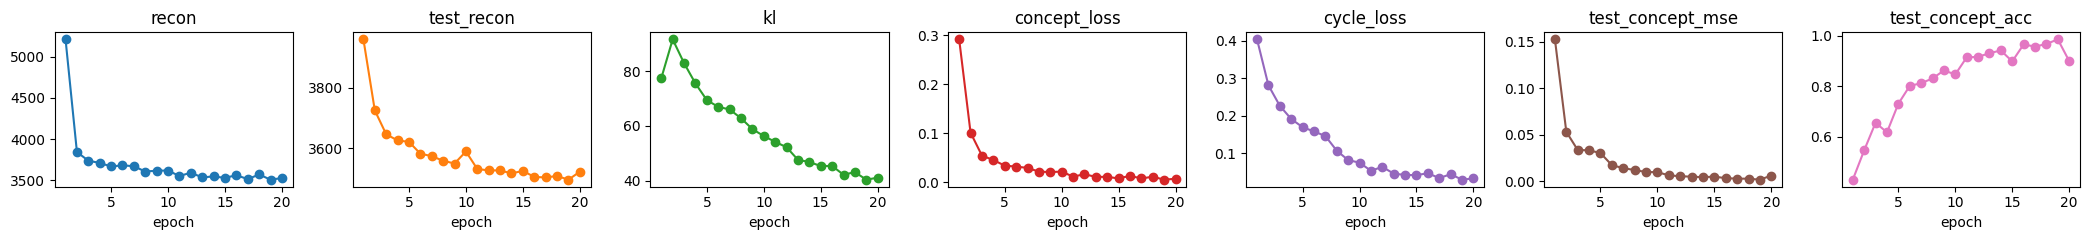

,epoch,recon,kl,concept_loss,cycle_loss,test_recon,test_concept_mse,test_concept_acc
17,18,3570.922749,43.157452,0.011639,0.043674,3507.217346,0.002817,0.966732
18,19,3507.222068,40.379778,0.005463,0.029051,3494.733240,0.001712,0.985026
19,20,3527.394816,41.127488,0.007497,0.032525,3521.275220,0.006187,0.899577


In [5]:
m = pd.read_csv(RUN_DIR / "metrics.csv")
cols = [c for c in ["recon", "test_recon", "kl", "concept_loss", "cycle_loss",
                    "test_concept_mse", "test_concept_acc"] if c in m and m[c].abs().sum() > 0]
m.plot(x="epoch", y=cols, subplots=True, layout=(1, len(cols)), figsize=(3 * len(cols), 2.5), legend=False,
       title=cols, marker="o")
plt.tight_layout(); plt.show()
m.tail(3)

## 3. Reconstructions and prior samples
Row 1: test images · Row 2: reconstructions · Row 3: fresh samples from $z\sim\mathcal N(0, I)$ (concepts predicted from $z$).

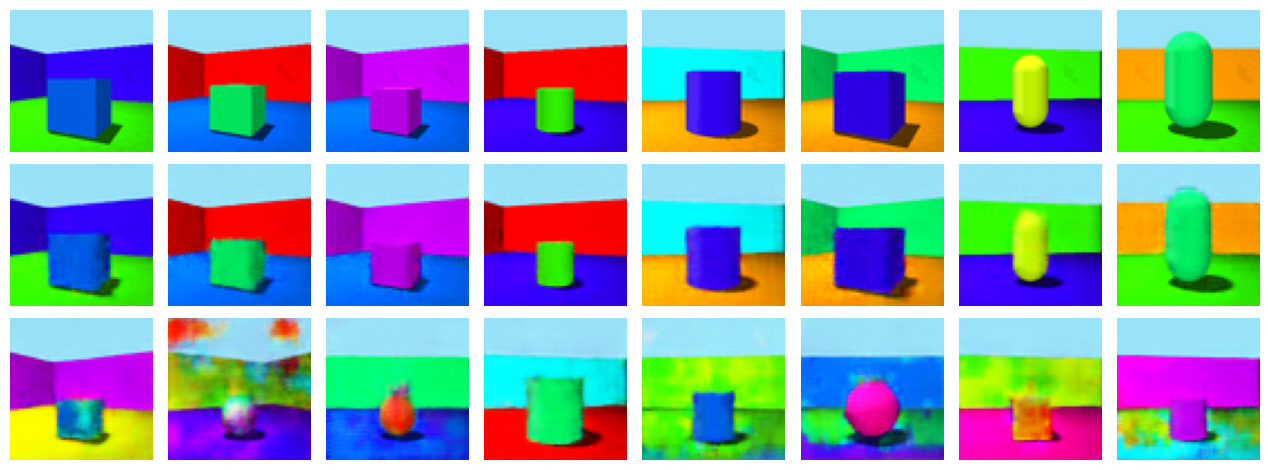

                                                                                                         true                                                                                                                   predicted
0   [0.30000001192092896, 0.699999988079071, 0.6000000238418579, 1.1100000143051147, 0.0, 25.709999084472656]                    [0.28999999165534973, 0.699999988079071, 0.6100000143051147, 1.090000033378601, 0.0, 25.860000610351562]
1                  [0.6000000238418579, 0.0, 0.4000000059604645, 0.9599999785423279, 0.0, 25.709999084472656]                  [0.6399999856948853, 0.019999999552965164, 0.4699999988079071, 0.949999988079071, 0.0, 24.899999618530273]
2     [0.6000000238418579, 0.800000011920929, 0.800000011920929, 0.8899999856948853, 0.0, 25.709999084472656]                     [0.6100000143051147, 0.800000011920929, 0.8399999737739563, 0.8600000143051147, 0.0, 26.06999969482422]
3                  [0.699999988079071, 0.0, 0.30000001192092896,

In [6]:
x8 = x_test[:8]
rows = torch.cat([x8.float() / 255, gen.reconstruct(x8), gen.generate(8, seed=SEED_Z)])
show(rows, nrow=8)
if gen.has_concepts:
    pred = gen.predict_concepts(x8)
    print(pd.DataFrame({"true": c_test[:8].numpy().round(2).tolist(),
                        "predicted": pred.numpy().round(2).tolist()}).to_string())

## 4. Interactive generation
Fixed `z` (pick the seed), one slider per concept. **auto** = leave that concept to the model (predicted from `z`); any other value is an intervention.
Continuous models (`cbm`, `cem`, `cem_linear`) also accept values *between* the training values; `binned` offers bin centres, `categorical` the native states.
For the plain VAE there are no concepts, so the sliders move the first latent dimensions instead.

In [7]:
out = W.Output()
seed_w = W.IntSlider(value=SEED_Z, min=0, max=200, description="z seed", continuous_update=False)

if gen.has_concepts:
    sliders = {}
    for name in gen.space.names:
        opts = [("auto", "auto")] + [(f"{v:.3g}", float(v)) for v in gen.space.slider_values(name)]
        sliders[name] = W.SelectionSlider(options=opts, value="auto", description=name,
                                          continuous_update=False,
                                          layout=W.Layout(width="420px"),
                                          style={"description_width": "90px"})
else:
    sliders = {f"z[{i}]": W.FloatSlider(value=0.0, min=-3, max=3, step=0.25, description=f"z[{i}]",
                                        continuous_update=False) for i in range(min(6, gen.latent_dim))}

def render(*_):
    with out:
        out.clear_output(wait=True)
        z = gen.prior(1, seed_w.value)
        if gen.has_concepts:
            chosen = {k: s.value for k, s in sliders.items() if s.value != "auto"}
            img, used = gen.generate(z=z, concepts=chosen, return_concepts=True)
            title = "  ".join(f"{k}={v:.2g}" for k, v in zip(gen.space.names, used[0].tolist()))
        else:
            for i, s in enumerate(sliders.values()):
                z[0, i] = s.value
            img, title = gen.generate(z=z), ""
        fig, ax = plt.subplots(figsize=(3.2, 3.2))
        ax.imshow(img[0].permute(1, 2, 0).numpy()); ax.axis("off")
        ax.set_title(title, fontsize=7, wrap=True)
        plt.show()

for w in [seed_w, *sliders.values()]:
    w.observe(render, names="value")
display(W.HBox([W.VBox([seed_w, *sliders.values()]), out]))
render()

## 5. Concept traversals
One fixed `z`; each row sweeps one concept over its range while the others stay as predicted.

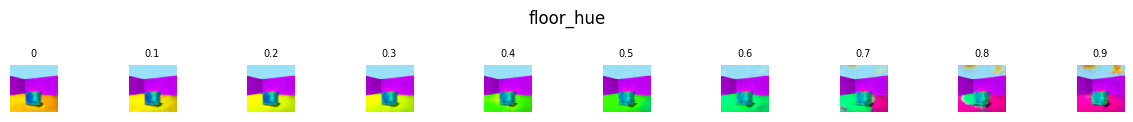

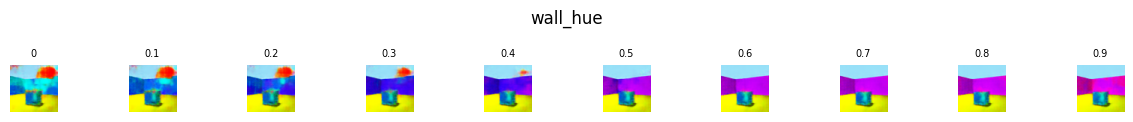

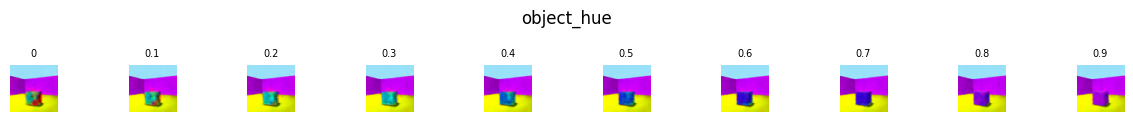

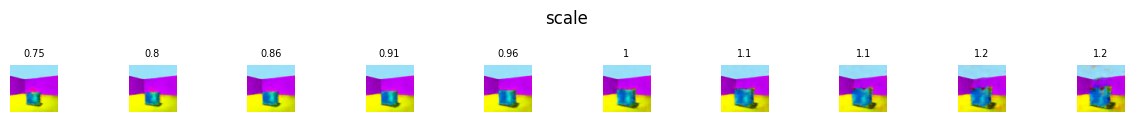

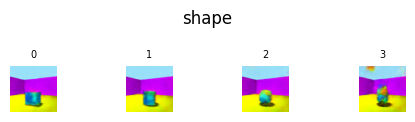

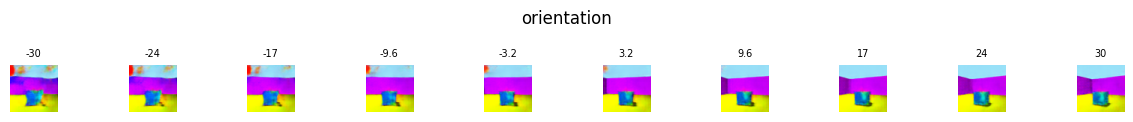

In [8]:
if gen.has_concepts:
    for name in gen.space.names:
        vals = gen.space.slider_values(name)
        if len(vals) > 10:                                   # keep rows readable
            vals = [vals[round(i * (len(vals) - 1) / 9)] for i in range(10)]
        show(gen.traverse(name, vals, seed=SEED_Z), titles=[f"{v:.2g}" for v in vals],
             nrow=len(vals), size=1.2, suptitle=name)
else:
    print("plain VAE: no concepts to traverse")

## 6. Edit a real image
Encode a test image, then decode it with some concepts changed.

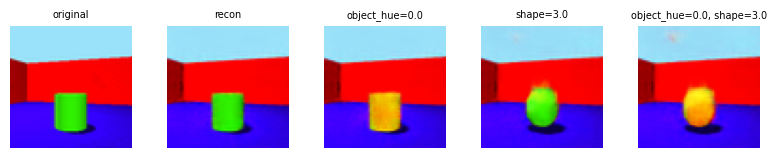

In [9]:
IDX  = 3
EDIT = {"object_hue": 0.0, "shape": 3.0}            # any subset of CONCEPTS, raw values

if gen.has_concepts:
    x1 = x_test[IDX:IDX + 1]
    edits = [{}] + [{k: v} for k, v in EDIT.items()] + [EDIT]
    imgs = torch.cat([x1.float() / 255] + [gen.reconstruct(x1, e) for e in edits])
    show(imgs, titles=["original", "recon"] + [", ".join(f"{k}={v}" for k, v in e.items()) for e in edits[1:]])

## 7. Compare every saved model
Same `z` seed and the same interventions for each model in `outputs/models/shapes3d_*`.

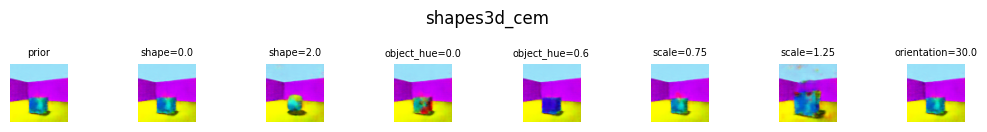

In [10]:
COMPARE_CONCEPTS = [{}, {"shape": 0.0}, {"shape": 2.0}, {"object_hue": 0.0}, {"object_hue": 0.6},
                    {"scale": 0.75}, {"scale": 1.25}, {"orientation": 30.0}]

for run in list_saved():
    g = gen if run == RUN_DIR else load(run, device=DEVICE)
    z = g.prior(1, SEED_Z)
    imgs = []
    for cc in COMPARE_CONCEPTS:
        ok = {k: v for k, v in cc.items() if g.has_concepts and k in g.space.names}
        imgs.append(g.generate(z=z, concepts=ok or None))
    show(torch.cat(imgs), titles=[", ".join(f"{k}={v}" for k, v in c.items()) or "prior" for c in COMPARE_CONCEPTS],
         nrow=len(COMPARE_CONCEPTS), size=1.3, suptitle=run.name)